In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from sklearn import metrics
from sklearn.model_selection import train_test_split

In [2]:
data = pd.read_excel(r'paris_house_prices.xlsx')

In [3]:
data.head()

,squareMeters,numberOfRooms,hasYard,hasPool,floors,cityCode,cityPartRange,numPrevOwners,made,isNewBuilt,hasStormProtector,basement,attic,garage,hasStorageRoom,hasGuestRoom,price
0,75523,3,no,yes,63,9373,3,8,2005,no,yes,4313,9005,956,no,7,7559081.5
1,80771,39,yes,yes,98,39381,8,6,2015,yes,no,3653,2436,128,yes,2,8085989.5
2,55712,58,no,yes,19,34457,6,8,2021,no,no,2937,8852,135,yes,9,5574642.1
3,32316,47,no,no,6,27939,10,4,2012,no,yes,659,7141,359,no,3,3232561.2
4,70429,19,yes,yes,90,38045,3,7,1990,yes,no,8435,2429,292,yes,4,7055052.0


In [4]:
data.shape

(10000, 17)

In [5]:
data.describe(include = 'all')

,squareMeters,numberOfRooms,hasYard,hasPool,floors,cityCode,cityPartRange,numPrevOwners,made,isNewBuilt,hasStormProtector,basement,attic,garage,hasStorageRoom,hasGuestRoom,price
count,10000.00000,10000.000000,10000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000,10000,10000.000000,10000.00000,10000.00000,10000,10000.00000,1.000000e+04
unique,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,2,2,NaN,NaN,NaN,2,NaN,NaN
top,NaN,NaN,yes,no,NaN,NaN,NaN,NaN,NaN,no,no,NaN,NaN,NaN,yes,NaN,NaN
freq,NaN,NaN,5087,5032,NaN,NaN,NaN,NaN,NaN,5009,5001,NaN,NaN,NaN,5030,NaN,NaN
mean,49870.13120,50.358400,NaN,NaN,50.276300,50225.486100,5.510100,5.521700,2005.48850,NaN,NaN,5033.103900,5028.01060,553.12120,NaN,4.99460,4.993448e+06
std,28774.37535,28.816696,NaN,NaN,28.889171,29006.675799,2.872024,2.856667,9.30809,NaN,NaN,2876.729545,2894.33221,262.05017,NaN,3.17641,2.877424e+06
min,89.00000,1.000000,NaN,NaN,1.000000,3.000000,1.000000,1.000000,1990.00000,NaN,NaN,0.000000,1.00000,100.00000,NaN,0.00000,1.031350e+04
25%,25098.50000,25.000000,NaN,NaN,25.000000,24693.750000,3.000000,3.000000,1997.00000,NaN,NaN,2559.750000,2512.00000,327.75000,NaN,2.00000,2.516402e+06
50%,50105.50000,50.000000,NaN,NaN,50.000000,50693.000000,5.000000,5.000000,2005.50000,NaN,NaN,5092.500000,5045.00000,554.00000,NaN,5.00000,5.016180e+06
75%,74609.75000,75.000000,NaN,NaN,76.000000,75683.250000,8.000000,8.000000,2014.00000,NaN,NaN,7511.250000,7540.50000,777.25000,NaN,8.00000,7.469092e+06


In [6]:
data.drop('cityCode', axis=1, inplace=True)

In [7]:
data.dtypes

,0
squareMeters,int64
numberOfRooms,int64
hasYard,object
hasPool,object
floors,int64
cityPartRange,int64
numPrevOwners,int64
made,int64
isNewBuilt,object
hasStormProtector,object


In [8]:
data.isnull().sum()

,0
squareMeters,0
numberOfRooms,0
hasYard,0
hasPool,0
floors,0
cityPartRange,0
numPrevOwners,0
made,0
isNewBuilt,0
hasStormProtector,0


In [9]:
dumm = pd.get_dummies(data, drop_first = True)
dumm.isnull().sum()

,0
squareMeters,0
numberOfRooms,0
floors,0
cityPartRange,0
numPrevOwners,0
made,0
basement,0
attic,0
garage,0
hasGuestRoom,0


In [10]:
data

,squareMeters,numberOfRooms,hasYard,hasPool,floors,cityPartRange,numPrevOwners,made,isNewBuilt,hasStormProtector,basement,attic,garage,hasStorageRoom,hasGuestRoom,price
0,75523,3,no,yes,63,3,8,2005,no,yes,4313,9005,956,no,7,7559081.5
1,80771,39,yes,yes,98,8,6,2015,yes,no,3653,2436,128,yes,2,8085989.5
2,55712,58,no,yes,19,6,8,2021,no,no,2937,8852,135,yes,9,5574642.1
3,32316,47,no,no,6,10,4,2012,no,yes,659,7141,359,no,3,3232561.2
4,70429,19,yes,yes,90,3,7,1990,yes,no,8435,2429,292,yes,4,7055052.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1726,89,no,yes,5,7,6,2009,no,yes,9311,1698,218,no,4,176425.9
9996,44403,29,yes,yes,12,9,4,1990,no,yes,9061,1742,230,no,0,4448474.0
9997,83841,3,no,no,69,10,10,2005,yes,yes,8304,7730,345,yes,9,8390030.5
9998,59036,70,no,no,96,1,3,2010,no,yes,2590,6174,339,yes,4,5905107.0


In [11]:
dumm

,squareMeters,numberOfRooms,floors,cityPartRange,numPrevOwners,made,basement,attic,garage,hasGuestRoom,price,hasYard_yes,hasPool_yes,isNewBuilt_yes,hasStormProtector_yes,hasStorageRoom_yes
0,75523,3,63,3,8,2005,4313,9005,956,7,7559081.5,False,True,False,True,False
1,80771,39,98,8,6,2015,3653,2436,128,2,8085989.5,True,True,True,False,True
2,55712,58,19,6,8,2021,2937,8852,135,9,5574642.1,False,True,False,False,True
3,32316,47,6,10,4,2012,659,7141,359,3,3232561.2,False,False,False,True,False
4,70429,19,90,3,7,1990,8435,2429,292,4,7055052.0,True,True,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1726,89,5,7,6,2009,9311,1698,218,4,176425.9,False,True,False,True,False
9996,44403,29,12,9,4,1990,9061,1742,230,0,4448474.0,True,True,False,True,False
9997,83841,3,69,10,10,2005,8304,7730,345,9,8390030.5,False,False,True,True,True
9998,59036,70,96,1,3,2010,2590,6174,339,4,5905107.0,False,False,False,True,True


In [12]:
inputs = dumm.drop('price', axis=1)
output = dumm['price']

X_train, X_test, y_train, y_test = train_test_split(inputs, output, test_size=0.3, random_state=42)

In [13]:
data.select_dtypes(include='object').columns

Index(['hasYard', 'hasPool', 'isNewBuilt', 'hasStormProtector',
       'hasStorageRoom'],
      dtype='object')

In [14]:
inputs_cat = data.drop('price', axis=1)
outputs_cat = data['price']

X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(inputs_cat, outputs_cat, test_size=0.3, random_state=42)

In [16]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.0 MB/s eta 0:00:00


In [17]:
models = []

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

xgb_model_def = XGBRegressor()
lgb_model_def = LGBMRegressor()
catboost_model_def = CatBoostRegressor()
catboost_model_custom = CatBoostRegressor(cat_features=['hasYard', 'hasPool', 'isNewBuilt', 'hasStormProtector',
       'hasStorageRoom'])


models.extend([
    ('XGBoost', xgb_model_def),
    ('LightGBM', lgb_model_def),
    ('CatBoost', catboost_model_def),
    ('CatBoost_Custom', catboost_model_custom)
])

In [21]:
def train_and_evaluate_model(model_name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)

    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Train metrics
    r2_train = metrics.r2_score(y_train, y_train_pred)

    # Test metrics
    mae_test = metrics.mean_absolute_error(y_test, y_test_pred)
    mse_test = metrics.mean_squared_error(y_test, y_test_pred)
    rmse_test = np.sqrt(mse_test)
    r2_test = metrics.r2_score(y_test, y_test_pred)

    print(f'Model Performance for {model_name}')
    print(f'Train R2: {r2_train:.4f}')
    print(f'Test MAE: {mae_test:.4f}')
    print(f'Test MSE: {mse_test:.4f}')
    print(f'Test RMSE: {rmse_test:.4f}')
    print(f'Test R2: {r2_test:.4f}')

    return r2_train, r2_test


In [22]:
r2_df = pd.DataFrame(columns=['Model', 'Train_R2', 'Test_R2'])

for model_name, model in models:
    if model_name == 'CatBoost_Custom':
        r2_train, r2_test = train_and_evaluate_model(model_name, model, X_train_cat, y_train_cat, X_test_cat, y_test_cat)
    else:
        r2_train, r2_test = train_and_evaluate_model(model_name, model, X_train, y_train, X_test, y_test)

    if r2_test is not None:
        r2_df = pd.concat([r2_df, pd.DataFrame({'Model': [model_name], 'Train_R2': [r2_train], 'Test_R2': [r2_test]})], ignore_index=True)

# Sort by Test_R2
r2_df_sorted = r2_df.sort_values(by='Test_R2', ascending=False)


Model Performance for XGBoost
Train R2: 1.0000
Test MAE: 11753.1033
Test MSE: 209435019.7444
Test RMSE: 14471.8699
Test R2: 1.0000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000361 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1298
[LightGBM] [Info] Number of data points in the train set: 7000, number of used features: 15
[LightGBM] [Info] Start training from score 4946359.529911


<ipython-input-22-2d10a9419502>:10: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  r2_df = pd.concat([r2_df, pd.DataFrame({'Model': [model_name], 'Train_R2': [r2_train], 'Test_R2': [r2_test]})], ignore_index=True)


Model Performance for LightGBM
Train R2: 1.0000
Test MAE: 10499.7994
Test MSE: 155553445.1796
Test RMSE: 12472.1067
Test R2: 1.0000
Learning rate set to 0.055681
0:	learn: 2708920.1445537	total: 2.74ms	remaining: 2.73s
1:	learn: 2570450.1489003	total: 5.29ms	remaining: 2.64s
2:	learn: 2439912.3039700	total: 7.78ms	remaining: 2.59s
3:	learn: 2311948.8809748	total: 10.3ms	remaining: 2.58s
4:	learn: 2194115.6562148	total: 12.9ms	remaining: 2.56s
5:	learn: 2079695.6808204	total: 15.4ms	remaining: 2.55s
6:	learn: 1972795.1099428	total: 17.7ms	remaining: 2.52s
7:	learn: 1872025.4428925	total: 20.3ms	remaining: 2.52s
8:	learn: 1775592.4250261	total: 22.8ms	remaining: 2.51s
9:	learn: 1686587.7518817	total: 25.3ms	remaining: 2.51s
10:	learn: 1603309.8504982	total: 27.9ms	remaining: 2.51s
11:	learn: 1525635.9396256	total: 30.4ms	remaining: 2.51s
12:	learn: 1447744.8088653	total: 33ms	remaining: 2.5s
13:	learn: 1372748.4706055	total: 35.4ms	remaining: 2.49s
14:	learn: 1302566.1071778	total: 38ms	

In [23]:
r2_df_sorted

,Model,Train_R2,Test_R2
1,LightGBM,0.999986,0.999982
0,XGBoost,0.999994,0.999975
2,CatBoost,0.999973,0.999959
3,CatBoost_Custom,0.999973,0.999958


In [24]:
## XGB with Optuna

In [25]:
pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 386.6/386.6 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.9/231.9 kB 20.8 MB/s eta 0:00:00


In [26]:
from sklearn.model_selection import cross_val_score
import optuna

def best_params_for_model(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 10, 1000),
        'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'subsample': trial.suggest_uniform('subsample', 0.5,1), #  fraction of the training data used to train each tree.
         # Using a fraction of the data can help to prevent overfitting and improve generalization.
        'colsample_bytree': trial.suggest_uniform('colsample_bytree', 0.5,1),
        'gamma': trial.suggest_int('gamma', 0,5)
        # Increasing the gamma value can help to prevent overfitting
        # Should be used only when you are using high depth
}
    xgb_reg = XGBRegressor(**param)

    auc = cross_val_score(xgb_reg, X_train, y_train, cv=3, scoring='r2', n_jobs=-1).mean()
    return auc



study = optuna.create_study(direction='maximize')
study.optimize(best_params_for_model, n_trials=1)

print('Best trial:')
best_params = study.best_params
print('  Value: {:.3f}'.format(study.best_value))
print('  Params: ', best_params)

best_xgb_model = XGBRegressor(**best_params)

[I 2025-04-26 09:44:13,187] A new study created in memory with name: no-name-c33355d9-a933-40e8-a871-3246bd91b6ba
<ipython-input-26-8beb526df94e>:7: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 1.0),
<ipython-input-26-8beb526df94e>:9: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  'subsample': trial.suggest_uniform('subsample', 0.5,1), #  fraction of the training data used to train each tree.
<ipython-input-26-8beb526df94e>:11: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  'colsample

Best trial:
  Value: 0.998
  Params:  {'n_estimators': 514, 'learning_rate': 0.28379911554580717, 'max_depth': 6, 'subsample': 0.6357264617008391, 'colsample_bytree': 0.9213551165152258, 'gamma': 0}


In [27]:
from sklearn.model_selection import cross_val_score
import optuna

def best_params_for_model(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 10, 1000),
        'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100)
    }

    lgb_reg = LGBMRegressor(**param)

    auc = cross_val_score(lgb_reg, X_train, y_train, cv=3, scoring='r2', n_jobs=-1).mean()
    return auc

study = optuna.create_study(direction='maximize')
study.optimize(best_params_for_model, n_trials=1)

print('Best trial:')
best_params = study.best_params
print('  Value: {:.3f}'.format(study.best_value))
print('  Params: ', best_params)

best_lgb_model = LGBMRegressor(**best_params)

[I 2025-04-26 09:44:25,710] A new study created in memory with name: no-name-e9ef7cb8-1c0f-41f8-ad3e-0ab82db1694e
<ipython-input-27-af6d6b40ba51>:7: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 1.0),
[I 2025-04-26 09:44:31,600] Trial 0 finished with value: 0.9999457258055724 and parameters: {'n_estimators': 490, 'learning_rate': 0.1922509569556371, 'max_depth': 3, 'num_leaves': 50}. Best is trial 0 with value: 0.9999457258055724.


Best trial:
  Value: 1.000
  Params:  {'n_estimators': 490, 'learning_rate': 0.1922509569556371, 'max_depth': 3, 'num_leaves': 50}


In [28]:
def best_params_for_model(trial):

    param = {
        'iterations': trial.suggest_int('iterations', 100, 1000),
        'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 1.0),
        'depth': trial.suggest_int('depth', 3, 10),
        'l2_leaf_reg': trial.suggest_loguniform('l2_leaf_reg', 0.1, 10), # Regularization term that prevents overfitting by penalizing large parameter values.
        # 'cat_features': [],  # Handle categorical features separately
        'loss_function': trial.suggest_categorical('loss_function', ['RMSE']) # For regression tasks, use ‘RMSE,’ while for classification, use ‘Logloss’.
    }

    cb_reg = CatBoostRegressor(**param)

    auc = cross_val_score(cb_reg, X_train, y_train, cv=3, scoring='r2', n_jobs=-1).mean()
    return auc



study = optuna.create_study(direction='maximize')
study.optimize(best_params_for_model, n_trials=1)

print('Best trial:')
best_params = study.best_params
print('  Value: {:.3f}'.format(study.best_value))
print('  Params: ', best_params)

best_cb_model = CatBoostRegressor(**best_params)

[I 2025-04-26 09:44:31,617] A new study created in memory with name: no-name-f8357fde-ba94-489a-902f-144ef2e13c64
<ipython-input-28-1f7b540e2d27>:5: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 1.0),
<ipython-input-28-1f7b540e2d27>:7: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'l2_leaf_reg': trial.suggest_loguniform('l2_leaf_reg', 0.1, 10), # Regularization term that prevents overfitting by penalizing large parameter values.
[I 2025-04-26 09:45:04,940] Trial 0 finished with value: 0.9974549104656484 and parameters: {'iterations': 870, 'learning_rate': 0.9369866977933287, 'depth': 9, 'l2_leaf_reg': 1.92

Best trial:
  Value: 0.997
  Params:  {'iterations': 870, 'learning_rate': 0.9369866977933287, 'depth': 9, 'l2_leaf_reg': 1.9210989842672215, 'loss_function': 'RMSE'}


In [29]:
models_optimized = []

models_optimized.extend([
    ('XGBoost Optuna', best_xgb_model),
    ('LightGBM Optuna', best_lgb_model),
    ('CatBoost Optuna', best_cb_model)
])

In [30]:
r2_df_optuna = pd.DataFrame(columns=['Model', 'Train_R2', 'Test_R2'])

for model_name, model in models_optimized:
    r2_train, r2_test = train_and_evaluate_model(model_name, model, X_train, y_train, X_test, y_test)

    if r2_test is not None:
        r2_df_optuna = pd.concat([r2_df_optuna, pd.DataFrame({
            'Model': [model_name],
            'Train_R2': [r2_train],
            'Test_R2': [r2_test]
        })], ignore_index=True)

r2_df_sorted_optuna = r2_df_optuna.sort_values(by='Test_R2', ascending=False)


Model Performance for XGBoost Optuna
Train R2: 1.0000
Test MAE: 65509.8494
Test MSE: 15966909164.7489
Test RMSE: 126360.2357
Test R2: 0.9981
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000384 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1298
[LightGBM] [Info] Number of data points in the train set: 7000, number of used features: 15
[LightGBM] [Info] Start training from score 4946359.529911
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

<ipython-input-30-45e881982f85>:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  r2_df_optuna = pd.concat([r2_df_optuna, pd.DataFrame({


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

In [31]:

r2_df_sorted_optuna


,Model,Train_R2,Test_R2
1,LightGBM Optuna,0.999982,0.999976
2,CatBoost Optuna,1.000000,0.998989
0,XGBoost Optuna,0.999999,0.998127


In [33]:
final_review = pd.concat([r2_df_sorted,r2_df_sorted_optuna], axis=0)

final_review_sorted = final_review.sort_values(by='Test_R2', ascending=False)
final_review_sorted.reset_index(drop=True, inplace=True)

final_review_sorted

,Model,Train_R2,Test_R2
0,LightGBM,0.999986,0.999982
1,LightGBM Optuna,0.999982,0.999976
2,XGBoost,0.999994,0.999975
3,CatBoost,0.999973,0.999959
4,CatBoost_Custom,0.999973,0.999958
5,CatBoost Optuna,1.000000,0.998989
6,XGBoost Optuna,0.999999,0.998127


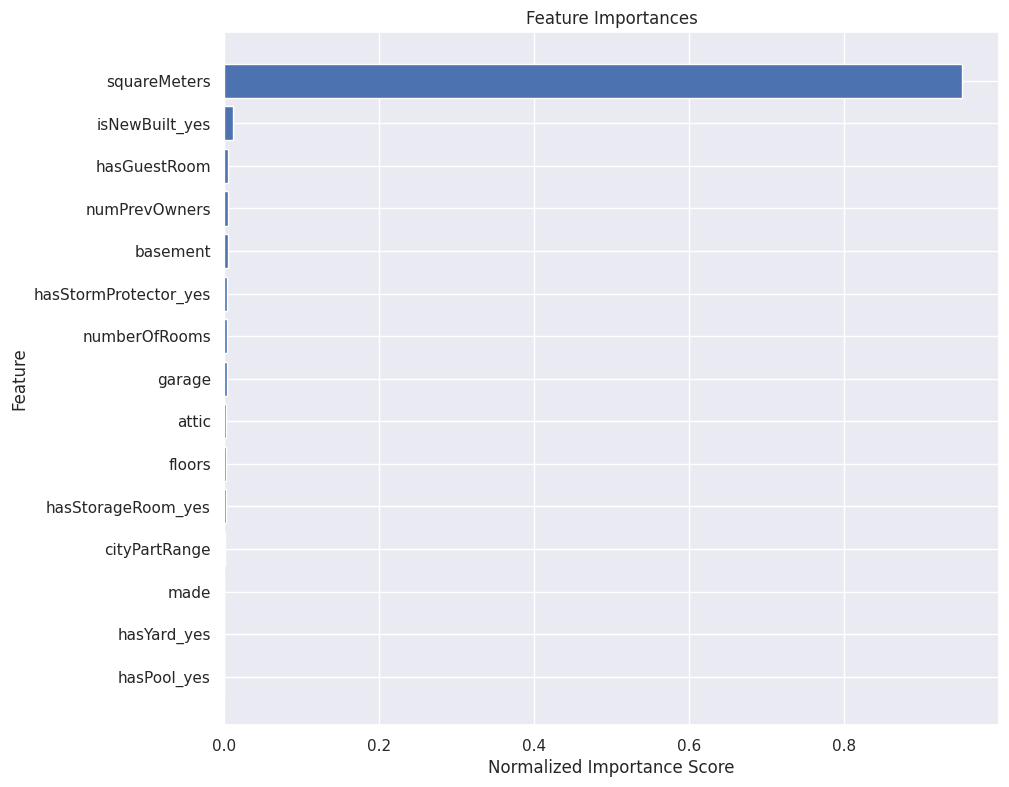

In [34]:
import matplotlib.pyplot as plt

importances = best_xgb_model.feature_importances_


importances = importances / importances.sum()

importance_df = pd.DataFrame({
        'Feature':  X_train.columns,
        'Importance': importances
    }).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 9))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.title("Feature Importances")
plt.xlabel("Normalized Importance Score")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.show()